<a href="https://colab.research.google.com/github/naik-aarya/Heart-Attack-Risk-Classification/blob/main/Heart_Attack_Risk_Classification_Aarya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Heart Attack Risk Classification**

**data**: https://drive.google.com/file/d/1f2xa7M4m3n14d2SGPIy-4e1PjUa-2Zeg/view?usp=sharing

## **Problem Statement**
The goal of this project is to develop a **classification model** that can predict the likelihood of a **heart attack** based on various **patient health indicators**. The dataset contains information on patients' demographic details, medical history, and diagnostic measures. The primary objective is to accurately classify patients into two categories: those with a higher likelihood of experiencing a heart attack (**target = 1**) and those with a lower likelihood (**target = 0**).

# **Objective**



The objective of this project is to build and evaluate a **machine learning classification model** that can predict the likelihood of a **heart attack** using **patient health** and **medical attributes**.

The model aims to analyze factors such as age, cholesterol level, blood pressure, chest pain type, heart rate, and other clinical indicators to classify patients into two categories:

Target = 1: Higher risk of heart attack

Target = 0: Lower risk of heart attack

**The project also focuses on:**

- Identifying the most important factors influencing heart attack risk
- Improving prediction accuracy using suitable preprocessing and machine learning algorithms
- Assisting healthcare professionals in early risk detection and decision-making
- Reducing the chances of delayed diagnosis - through data-driven predictions
Comparing multiple classification algorithms to select the best-performing model based on evaluation metrics such as accuracy, precision, recall, F1-score, and ROC-AUC score

# **Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#**Load Data**

In [ ]:
data = pd.read_csv('heart.csv')

In [ ]:
data

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


# **Understanding Variables**

| Column Name        | Description                                                   | Medical Importance                                                                                                            |
| ------------------ | ------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------- |
| **Age**            | Age of the patient in years                                   | Risk of heart disease generally increases with age due to weakening cardiovascular health.                                    |
| **Sex**            | Gender of the patient (`M = Male`, `F = Female`)              | Men are generally at higher risk of heart disease at an earlier age compared to women.                                        |
| **ChestPainType**  | Type of chest pain experienced by the patient                 | Chest pain is one of the major indicators of heart-related problems. Different pain types indicate different severity levels. |
|                    | **ATA** = Atypical Angina                                     | Chest pain not strongly related to heart disease.                                                                             |
|                    | **NAP** = Non-Anginal Pain                                    | Chest pain not caused by heart issues.                                                                                        |
|                    | **ASY** = Asymptomatic                                        | No chest pain symptoms but may still have heart disease. Often considered high risk.                                          |
|                    | **TA** = Typical Angina                                       | Classic heart-related chest pain due to reduced blood flow to the heart.                                                      |
| **RestingBP**      | Resting Blood Pressure (in mm Hg)                             | High blood pressure increases strain on the heart and arteries, increasing heart attack risk.                                 |
| **Cholesterol**    | Serum cholesterol level (mg/dL)                               | High cholesterol can lead to plaque buildup in arteries, increasing cardiovascular risk.                                      |
| **FastingBS**      | Fasting Blood Sugar (`1 = >120 mg/dL`, `0 = Normal`)          | High fasting blood sugar may indicate diabetes, a major risk factor for heart disease.                                        |
| **RestingECG**     | Resting Electrocardiogram results                             | Measures electrical activity of the heart to detect abnormalities.                                                            |
|                    | **Normal**                                                    | Normal ECG result                                                                                                             |
|                    | **ST**                                                        | ST-T wave abnormality indicating possible heart stress or damage                                                              |
|                    | **LVH**                                                       | Left Ventricular Hypertrophy – enlargement of heart muscle due to high blood pressure or heart issues                         |
| **MaxHR**          | Maximum heart rate achieved during exercise                   | Lower maximum heart rate during activity may indicate cardiovascular problems.                                                |
| **ExerciseAngina** | Exercise-induced angina (`Y = Yes`, `N = No`)                 | Chest pain during physical activity may indicate reduced blood supply to the heart.                                           |
| **Oldpeak**        | ST depression induced by exercise relative to rest            | Indicates abnormal heart activity during stress/exercise. Higher values may indicate severe heart disease.                    |
| **ST_Slope**       | Slope of the peak exercise ST segment                         | Important ECG-related feature for detecting heart disease.                                                                    |
|                    | **Up**                                                        | Upward slope – generally considered normal                                                                                    |
|                    | **Flat**                                                      | Flat slope – may indicate heart disease                                                                                       |
|                    | **Down**                                                      | Downward slope – strong indicator of heart-related abnormalities                                                              |
| **HeartDisease**   | Target variable (`1 = Heart Disease`, `0 = No Heart Disease`) | Represents whether the patient is likely to have heart disease.                                                               |


# **Basic Checks**

In [ ]:
data.shape

(918, 12)

Data has **918** rows and **12** columns

In [ ]:
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
data.tail()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1
917,38,M,NAP,138,175,0,Normal,173,N,0.0,Up,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
data.dtypes

,0
Age,int64
Sex,object
ChestPainType,object
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,object
MaxHR,int64
ExerciseAngina,object
Oldpeak,float64


In [ ]:
data.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [ ]:
num_cols = data.select_dtypes(include=['int64','float64'])
num_cols

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
0,40,140,289,0,172,0.0,0
1,49,160,180,0,156,1.0,1
2,37,130,283,0,98,0.0,0
3,48,138,214,0,108,1.5,1
4,54,150,195,0,122,0.0,0
...,...,...,...,...,...,...,...
913,45,110,264,0,132,1.2,1
914,68,144,193,1,141,3.4,1
915,57,130,131,0,115,1.2,1
916,57,130,236,0,174,0.0,1


In [ ]:
cat_cols = data.select_dtypes(include=['object'])
cat_cols

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
0,M,ATA,Normal,N,Up
1,F,NAP,Normal,N,Flat
2,M,ATA,ST,N,Up
3,F,ASY,Normal,Y,Flat
4,M,NAP,Normal,N,Up
...,...,...,...,...,...
913,M,TA,Normal,N,Flat
914,M,ASY,Normal,N,Flat
915,M,ASY,Normal,Y,Flat
916,F,ATA,LVH,N,Flat


In [ ]:
data.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


There are no **constant columns**.

Values cannot be **0** for **RestingBP	Cholesterol**	columns. There are some incorrect 0 entries which needs to be corrected.



In [ ]:
# check for count of 0 in RestingBP	Cholesterol
print((data['RestingBP']==0).sum())
print((data['Cholesterol']==0).sum())

1
172


In [ ]:
data.describe(include='object')

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
count,918,918,918,918,918
unique,2,4,3,2,3
top,M,ASY,Normal,N,Flat
freq,725,496,552,547,460


In [ ]:
# print unique values
for x in cat_cols:
  print(x,'-->',data[x].unique())
  print()

Sex --> ['M' 'F']

ChestPainType --> ['ATA' 'NAP' 'ASY' 'TA']

RestingECG --> ['Normal' 'ST' 'LVH']

ExerciseAngina --> ['N' 'Y']

ST_Slope --> ['Up' 'Flat' 'Down']



In [ ]:
# print value counts
for x in cat_cols:
  print(x,data[x].value_counts())
  print()

Sex Sex
M    725
F    193
Name: count, dtype: int64

ChestPainType ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

RestingECG RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64

ExerciseAngina ExerciseAngina
N    547
Y    371
Name: count, dtype: int64

ST_Slope ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64



# **Data Preprocessing**

In [ ]:
# check for duplicates
data.duplicated().sum()

np.int64(0)

There are no duplicates.

In [ ]:
# check for missing values
data.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


There are no missing values in data.

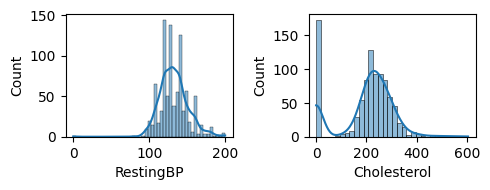

In [ ]:
# RestingBP	Cholesterol	 has few values has 0
# check the distribution
fig,ax = plt.subplots(1,2,figsize=(5,2))
sns.histplot(data,x='RestingBP',ax=ax[0],kde=True)
sns.histplot(data,x='Cholesterol',ax=ax[1],kde=True)
plt.tight_layout()

In [ ]:
A = ['RestingBP','Cholesterol']
for x in A:
  print(x,data[x].skew())

RestingBP 0.1798393100516288
Cholesterol -0.6100864307268192


**RestingBP** is normal because skewness is within [-0.5,0.5].

**Cholesterol** is left skewed.

In [ ]:
# will replace zeros in 'RestingBP','Cholesterol' with median
data['RestingBP']= data['RestingBP'].replace(0,data['RestingBP'].mean())
data['Cholesterol']= data['Cholesterol'].replace(0,data['Cholesterol'].median())

In [ ]:
print((data['RestingBP']==0).sum())
print((data['Cholesterol']==0).sum())

0
0


In [ ]:
data.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.540737,240.581699,0.233115,136.809368,0.887364,0.553377
std,9.432617,17.989932,53.982967,0.423046,25.460334,1.066570,0.497414
min,28.000000,80.000000,85.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,214.000000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


# **Exploratory Data Analysis**

**Univariate**

histogram,count,pie chart,box plot

**Check distribution of all numerical columns**

**Check are there outliers in numerical columns**

**Check count of all categories in categorical column**

**Bivariate**

line,scatter,bar chart

**Multivariate**

pair plot,heat map

# **Feature Engineering**

**Handle Outliers**

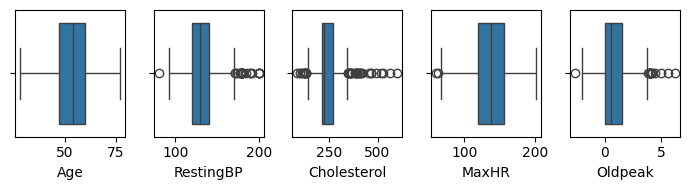

In [ ]:
df = data[['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']]
fig , ax= plt.subplots(1,5,figsize=(7,2))
sns.boxplot(data,x='Age',ax=ax[0])
sns.boxplot(data,x='RestingBP',ax=ax[1])
sns.boxplot(data,x='Cholesterol',ax=ax[2])
sns.boxplot(data,x='MaxHR',ax=ax[3])
sns.boxplot(data,x='Oldpeak',ax=ax[4])
plt.tight_layout()

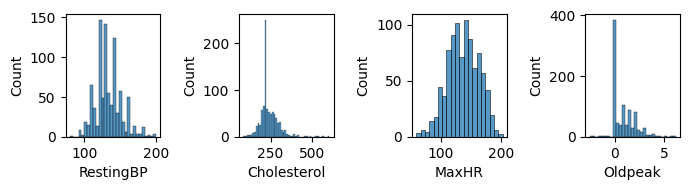

In [ ]:
# check the distribution
df = data[['RestingBP','Cholesterol','MaxHR','Oldpeak']]
fig , ax= plt.subplots(1,4,figsize=(7,2))
sns.histplot(data,x='RestingBP',ax=ax[0])
sns.histplot(data,x='Cholesterol',ax=ax[1])
sns.histplot(data,x='MaxHR',ax=ax[2])
sns.histplot(data,x='Oldpeak',ax=ax[3])
plt.tight_layout()

In [ ]:
# find skewness
df = data[['RestingBP','Cholesterol','MaxHR','Oldpeak']]
for x in df:
  print(x,df[x].skew())

RestingBP 0.6075508374550895
Cholesterol 1.5373598901439869
MaxHR -0.14435941846180994
Oldpeak 1.0228720218107528


Skew is within [-0.5,0.5]--> normal : mean

skew is less than -0.5-->left skew : median

skew is more than 0.5 --> right skew : median

**RestingBP**

Distribution is right skewed , use IQR

In [ ]:
Q1 = data['RestingBP'].quantile(0.25)
Q3 =  data['RestingBP'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1 - 1.5 *IQR
upper_limit = Q3 + 1.5*IQR

In [ ]:
data[data['RestingBP']<lower_limit]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
314,53,M,ASY,80.0,223,0,Normal,141,Y,2.0,Down,0


In [ ]:
data[data['RestingBP']>upper_limit]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
109,39,M,ATA,190.0,241,0,Normal,106,N,0.0,Up,0
123,58,F,ATA,180.0,393,0,Normal,110,Y,1.0,Flat,1
189,53,M,ASY,180.0,285,0,ST,120,Y,1.5,Flat,1
190,46,M,ASY,180.0,280,0,ST,120,N,0.0,Up,0
241,54,M,ASY,200.0,198,0,Normal,142,Y,2.0,Flat,1
274,45,F,ATA,180.0,295,0,Normal,180,N,0.0,Up,0
275,59,M,NAP,180.0,213,0,Normal,100,N,0.0,Up,0
278,57,F,ASY,180.0,347,0,ST,126,Y,0.8,Flat,0
365,64,F,ASY,200.0,223,0,Normal,140,Y,1.0,Flat,1
372,63,M,ASY,185.0,223,0,Normal,98,Y,0.0,Up,1


In [ ]:
len(data[(data['RestingBP']<lower_limit)|(data['RestingBP']>upper_limit)])/len(data)*100

2.941176470588235

Less than 5% lets replace with median

In [ ]:
data.loc[(data['RestingBP']<lower_limit)|(data['RestingBP']>upper_limit),'RestingBP']=data['RestingBP'].median()

In [ ]:
len(data[(data['RestingBP']<lower_limit)|(data['RestingBP']>upper_limit)])/len(data)*100

0.0

**Cholesterol**

Distribution is right skewed , use IQR

In [ ]:
Q1 = data['Cholesterol'].quantile(0.25)
Q3 =  data['Cholesterol'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1 - 1.5 *IQR
upper_limit = Q3 + 1.5*IQR

In [ ]:
data[data['Cholesterol']<lower_limit]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
78,52,M,ATA,140.0,100,0,Normal,138,Y,0.0,Up,0
98,56,M,ASY,120.0,85,0,Normal,140,N,0.0,Up,0
108,50,M,ASY,140.0,129,0,Normal,135,N,0.0,Up,0
208,28,M,ATA,130.0,132,0,LVH,185,N,0.0,Up,0
227,38,M,ASY,92.0,117,0,Normal,134,Y,2.5,Flat,1
263,59,M,ASY,130.0,126,0,Normal,125,N,0.0,Flat,1
444,56,M,ASY,120.0,100,0,Normal,120,Y,1.5,Flat,1
541,76,M,NAP,104.0,113,0,LVH,120,N,3.5,Down,1
571,69,M,ASY,140.0,110,1,Normal,109,Y,1.5,Flat,1
573,72,M,ASY,160.0,123,1,LVH,130,N,1.5,Flat,1


In [ ]:
data[data['Cholesterol']>upper_limit]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
28,53,F,ATA,113.0,468,0,Normal,127,N,0.0,Up,0
30,53,M,NAP,145.0,518,0,Normal,130,N,0.0,Flat,1
58,54,M,ASY,150.0,365,0,ST,134,N,1.0,Up,0
69,44,M,ASY,150.0,412,0,Normal,170,N,0.0,Up,0
76,32,M,ASY,118.0,529,0,Normal,130,N,0.0,Flat,1
102,40,F,ASY,150.0,392,0,Normal,130,N,2.0,Flat,1
103,40,M,ASY,120.0,466,1,Normal,152,Y,1.0,Flat,1
123,58,F,ATA,130.0,393,0,Normal,110,Y,1.0,Flat,1
132,56,M,ASY,170.0,388,0,ST,122,Y,2.0,Flat,1
149,54,M,ASY,130.0,603,1,Normal,125,Y,1.0,Flat,1


In [ ]:
len(data[(data['Cholesterol']<lower_limit)|(data['Cholesterol']>upper_limit)])/len(data)*100

4.466230936819173

In [ ]:
data.loc[(data['Cholesterol']<lower_limit)|(data['Cholesterol']>upper_limit),'Cholesterol']=data['Cholesterol'].median()

**Oldpeak**

Distribution of Oldpeak is skewed , use IQR

In [ ]:
Q1 = data['Oldpeak'].quantile(0.25)
Q3 =  data['Oldpeak'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1 - 1.5 *IQR
upper_limit = Q3 + 1.5*IQR

In [ ]:
data[data['Oldpeak']<lower_limit]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
324,46,M,ASY,100.0,223,1,ST,133,N,-2.6,Flat,1


In [ ]:
data[data['Oldpeak']>upper_limit]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
68,52,M,ASY,160.0,246,0,ST,82,Y,4.0,Flat,1
166,50,M,ASY,140.0,231,0,ST,140,Y,5.0,Flat,1
500,65,M,ASY,136.0,248,0,Normal,140,Y,4.0,Down,1
521,61,M,ASY,120.0,282,0,ST,135,Y,4.0,Down,1
537,74,M,ASY,150.0,258,1,ST,130,Y,4.0,Down,1
559,64,M,ASY,134.0,273,0,Normal,102,Y,4.0,Down,1
624,63,F,ASY,150.0,223,0,LVH,154,N,4.0,Flat,1
702,59,M,TA,130.0,270,0,LVH,145,N,4.2,Down,0
732,56,F,ASY,130.0,288,1,LVH,133,Y,4.0,Down,1
771,55,M,ASY,140.0,217,0,Normal,111,Y,5.6,Down,1


In [ ]:
len(data[(data['Oldpeak']<lower_limit)|(data['Oldpeak']>upper_limit)])/len(data)*100

1.7429193899782136

In [ ]:
data.loc[(data['Oldpeak']<lower_limit)|(data['Oldpeak']>upper_limit),'Oldpeak']=data['Oldpeak'].median()

**MaxHR**

Distribution is normal , we use 3 sigma rule

In [ ]:
mean_val = data['MaxHR'].mean()
std_val = data['MaxHR'].std()
lower_limit = mean_val - 3 * std_val
upper_limit = mean_val +3 * std_val

In [ ]:
data[data['MaxHR']<lower_limit]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
390,51,M,ASY,140.0,223,0,Normal,60,N,0.0,Flat,1


In [ ]:
data[data['MaxHR']>upper_limit]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease


In [ ]:
len(data[(data['MaxHR']<lower_limit)|(data['MaxHR']>upper_limit)])/len(data)*100

0.10893246187363835

In [ ]:
data.loc[(data['MaxHR']<lower_limit)|(data['MaxHR']>upper_limit),'MaxHR']=data['MaxHR'].mean()

/tmp/ipykernel_319/1381324945.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '136.80936819172112' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[(data['MaxHR']<lower_limit)|(data['MaxHR']>upper_limit),'MaxHR']=data['MaxHR'].mean()


**Encoding**

In [ ]:
# Label Encoder : ExerciseAngina(Y,N)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['Exercise_Angina']= le.fit_transform(data['ExerciseAngina'])

In [ ]:
# One hot encoder : Sex (M , F)
data = pd.get_dummies(data,columns=['Sex'],dtype='int')

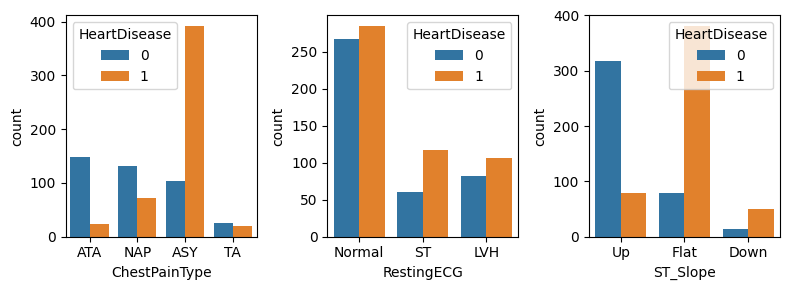

In [ ]:
# ChestPainType	RestingECG	ST_Slope
fig , ax = plt.subplots(1,3,figsize=(8,3))
sns.countplot(data,x='ChestPainType',ax=ax[0],hue='HeartDisease')
sns.countplot(data,x='RestingECG',ax=ax[1],hue='HeartDisease')
sns.countplot(data,x='ST_Slope',ax=ax[2],hue='HeartDisease')
plt.tight_layout()


In [ ]:
# ChestPainType
data = pd.get_dummies(data,columns=['ChestPainType'],dtype='int')

In [ ]:
# RestingECG
data = pd.get_dummies(data,columns=['RestingECG'],dtype='int')

In [ ]:
# ST_Slope
data = pd.get_dummies(data,columns=['ST_Slope'],dtype='int')

In [ ]:
# drop ExerciseAngina
data.drop(columns='ExerciseAngina',inplace=True)

**Scaling**

In [ ]:
# Standard Scaler
# Age	RestingBP	Cholesterol		MaxHR	Oldpeak
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
data[['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']]=sc.fit_transform(data[['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']])

In [ ]:
data

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Exercise_Angina,Sex_F,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.572072,1.339009,0,1.386546,-0.866238,0,0,0,1,0,1,0,0,0,1,0,0,0,1
1,-0.478484,1.855050,-1.407520,0,0.754627,0.178162,1,0,1,0,0,0,1,0,0,1,0,0,1,0
2,-1.751359,-0.069418,1.187824,0,-1.536076,-0.866238,0,0,0,1,0,1,0,0,0,0,1,0,0,1
3,-0.584556,0.443774,-0.550805,0,-1.141127,0.700363,1,1,1,0,1,0,0,0,0,1,0,0,1,0
4,0.051881,1.213561,-1.029557,0,-0.588199,-0.866238,0,0,0,1,0,0,1,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,-1.352396,0.709071,0,-0.193250,0.387042,1,0,0,1,0,0,0,1,0,1,0,0,1,0
914,1.536902,0.828667,-1.079953,1,0.162204,2.684723,1,0,0,1,1,0,0,0,0,1,0,0,1,0
915,0.370100,-0.069418,-0.324027,0,-0.864663,0.387042,1,1,0,1,1,0,0,0,0,1,0,0,1,0
916,0.370100,-0.069418,0.003541,0,1.465535,-0.866238,1,0,1,0,0,1,0,0,1,0,0,0,1,0


**Feature Selection**

In [ ]:
# All columns are important
# Check for Multicollinearity
df = data[['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']]
df.corr()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
Age,1.000000,0.268719,0.049242,-0.384837,0.254197
RestingBP,0.268719,1.000000,0.028601,-0.105100,0.165541
Cholesterol,0.049242,0.028601,1.000000,0.042831,0.063156
MaxHR,-0.384837,-0.105100,0.042831,1.000000,-0.174693
Oldpeak,0.254197,0.165541,0.063156,-0.174693,1.000000


<Axes: >

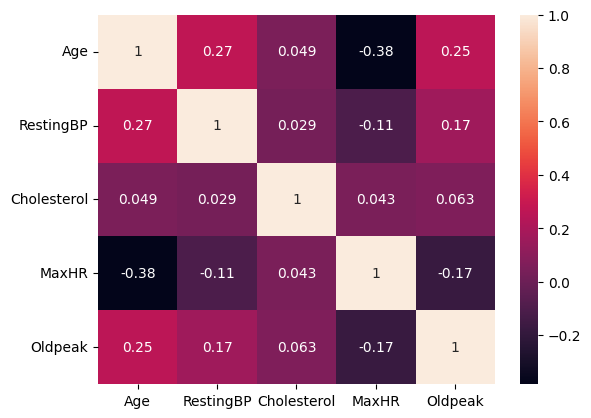

In [ ]:
sns.heatmap(df.corr(),annot=True)
# correlation between input variables should be less

**Split data for x and y**

In [ ]:
x = data.drop(columns='HeartDisease')
y = data['HeartDisease']

**Split data for training and testing**

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

**Check Whether data is balanced or not**

**Balanced Data**

In target column if number of observations in each category is same , we call it as balanced data.

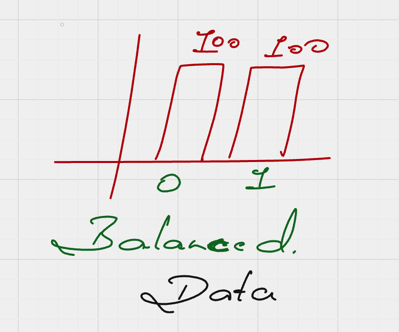

**Imbalanced Data**

In target column if number of observations in eacg category is different , we call it as Imbalanced data.

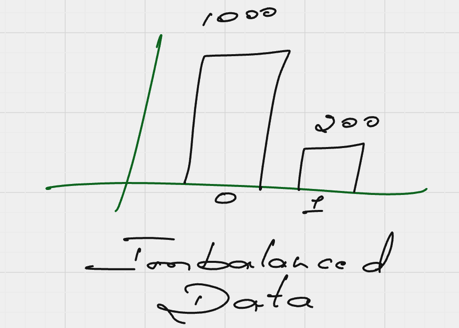

**Use count plot to check whether data is balanced or not**

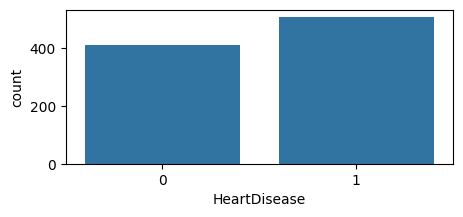

In [ ]:
plt.figure(figsize=(5,2))
sns.countplot(data,x='HeartDisease')
plt.show()

Clearly data is **Imbalanced** , which results in **biased model**. The models learns more about the class which **highest number of observations** which leads to bias.

**How to Balance**

- Oversampling
- Undersampling
- SMOTE

**Oversampling**

Increasing the number of observations in minority class(class with low observations) to match with majority class(class with high observations) by duplicating observations.

**Limitation**

Duplicates will increase

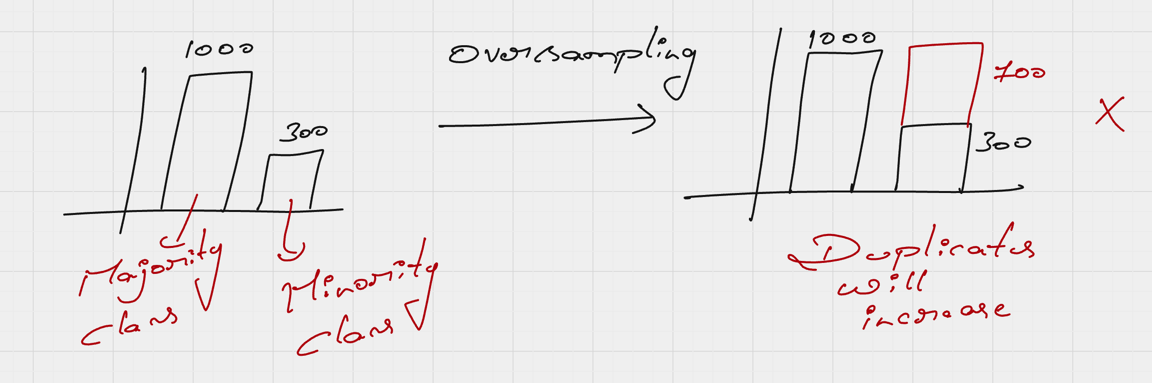

**Undersampling**

Process of reducing observations in majority class to match with minority class

**Limitation**

It results in loss of information/data.

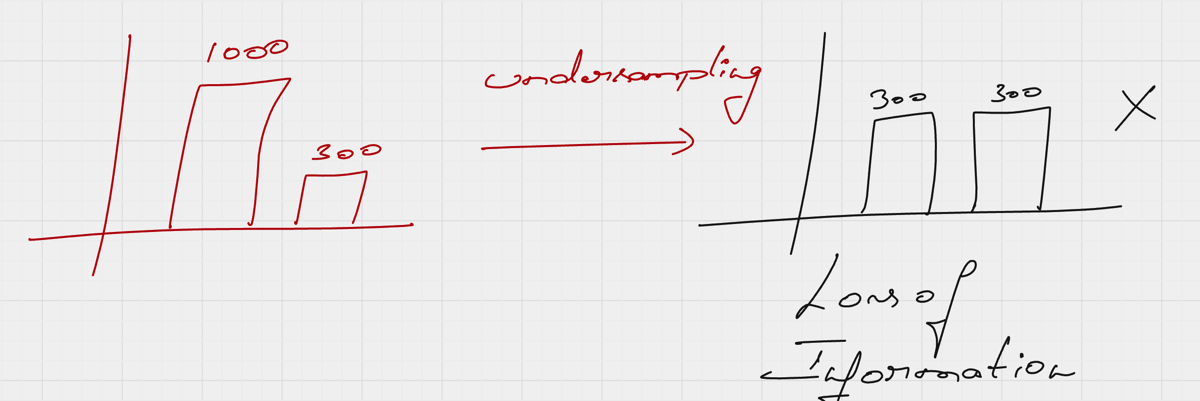

**SMOTE(Synthetic Minority Oversampling Technique)**

- SMOTE is used for balancing data.
- SMOTE is oversampling technique instead of duplicating minority samples , it creates synthetic samples.
- It generates new points between existing minority class samples.

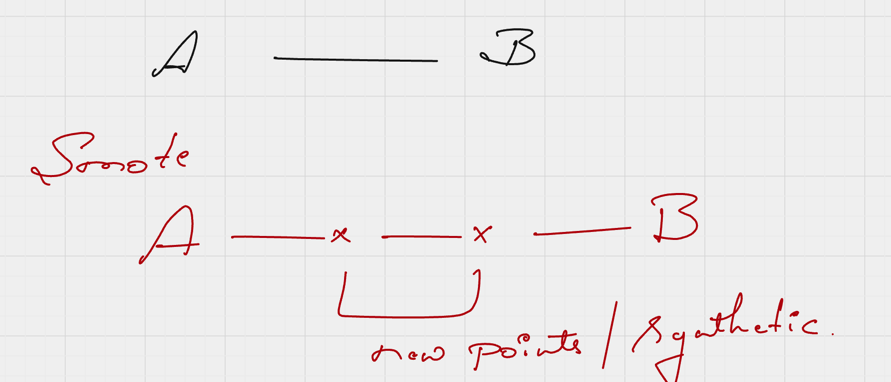

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter
smote = SMOTE()
# balancing should be done only on train data
x_sampled,y_sampled = smote.fit_resample(x_train,y_train)

In [ ]:
print(Counter(y_train))
print(Counter(y_sampled))

Counter({1: 401, 0: 333})
Counter({0: 401, 1: 401})


#**ModelBuilding**

In [ ]:
from sklearn.linear_model import LogisticRegression
log_model = LogisticRegression()
# train model
log_model.fit(x_sampled,y_sampled)
y_pred = log_model.predict(x_test)

In [ ]:
log_model.coef_ # slope

array([[ 0.16678672,  0.07269702,  0.04194912,  1.18871045, -0.20851113,
         0.35621772,  1.05218357, -0.1843427 ,  1.1419928 ,  1.66870939,
         0.05389533,  0.23320188,  0.50917038,  0.7616737 ,  0.70587313,
         0.58955609,  0.70429669,  1.59241858, -0.72509257]])

In [ ]:
log_model.intercept_ #intercept

array([-3.6579659])

In [ ]:
log_model.predict_proba(x_test) # probabilities for each class (given by sigmoid)
# class 0 : no heart attack
# class 1 : heart attack

array([[0.98656919, 0.01343081],
       [0.54835089, 0.45164911],
       [0.04275951, 0.95724049],
       [0.05893817, 0.94106183],
       [0.95114887, 0.04885113],
       [0.08165753, 0.91834247],
       [0.28629699, 0.71370301],
       [0.87988679, 0.12011321],
       [0.17526082, 0.82473918],
       [0.10074939, 0.89925061],
       [0.38086508, 0.61913492],
       [0.88634189, 0.11365811],
       [0.28204757, 0.71795243],
       [0.94470846, 0.05529154],
       [0.04143739, 0.95856261],
       [0.49410823, 0.50589177],
       [0.97129988, 0.02870012],
       [0.22936893, 0.77063107],
       [0.22657292, 0.77342708],
       [0.73273934, 0.26726066],
       [0.39493454, 0.60506546],
       [0.21781127, 0.78218873],
       [0.95499169, 0.04500831],
       [0.29745609, 0.70254391],
       [0.06773844, 0.93226156],
       [0.07422414, 0.92577586],
       [0.95576671, 0.04423329],
       [0.21773488, 0.78226512],
       [0.96597583, 0.03402417],
       [0.97511167, 0.02488833],
       [0.

In [ ]:
# class 0 probabilities
log_model.predict_proba(x_test)[:,0]

array([0.98656919, 0.54835089, 0.04275951, 0.05893817, 0.95114887,
       0.08165753, 0.28629699, 0.87988679, 0.17526082, 0.10074939,
       0.38086508, 0.88634189, 0.28204757, 0.94470846, 0.04143739,
       0.49410823, 0.97129988, 0.22936893, 0.22657292, 0.73273934,
       0.39493454, 0.21781127, 0.95499169, 0.29745609, 0.06773844,
       0.07422414, 0.95576671, 0.21773488, 0.96597583, 0.97511167,
       0.28921899, 0.84466433, 0.2113497 , 0.05168501, 0.17163569,
       0.6396608 , 0.04700967, 0.95518801, 0.05434507, 0.28845475,
       0.09575583, 0.17320722, 0.36035043, 0.84114343, 0.91754602,
       0.17631434, 0.2700313 , 0.02070152, 0.08348025, 0.66924388,
       0.95926771, 0.96900412, 0.20017213, 0.03928027, 0.28242776,
       0.81704089, 0.78228035, 0.0661334 , 0.41554584, 0.11930019,
       0.81882852, 0.92167528, 0.99188601, 0.02142981, 0.97340816,
       0.02322495, 0.00861279, 0.08288123, 0.01174777, 0.43769699,
       0.791911  , 0.94489139, 0.28706199, 0.55024803, 0.79208

In [ ]:
# class 1 probabilities
log_model.predict_proba(x_test)[:,1]

array([0.01343081, 0.45164911, 0.95724049, 0.94106183, 0.04885113,
       0.91834247, 0.71370301, 0.12011321, 0.82473918, 0.89925061,
       0.61913492, 0.11365811, 0.71795243, 0.05529154, 0.95856261,
       0.50589177, 0.02870012, 0.77063107, 0.77342708, 0.26726066,
       0.60506546, 0.78218873, 0.04500831, 0.70254391, 0.93226156,
       0.92577586, 0.04423329, 0.78226512, 0.03402417, 0.02488833,
       0.71078101, 0.15533567, 0.7886503 , 0.94831499, 0.82836431,
       0.3603392 , 0.95299033, 0.04481199, 0.94565493, 0.71154525,
       0.90424417, 0.82679278, 0.63964957, 0.15885657, 0.08245398,
       0.82368566, 0.7299687 , 0.97929848, 0.91651975, 0.33075612,
       0.04073229, 0.03099588, 0.79982787, 0.96071973, 0.71757224,
       0.18295911, 0.21771965, 0.9338666 , 0.58445416, 0.88069981,
       0.18117148, 0.07832472, 0.00811399, 0.97857019, 0.02659184,
       0.97677505, 0.99138721, 0.91711877, 0.98825223, 0.56230301,
       0.208089  , 0.05510861, 0.71293801, 0.44975197, 0.20791

In [ ]:
comparison=pd.DataFrame({'actual':y_test , 'predicted':y_pred,
                         'Prob_Class_0': log_model.predict_proba(x_test)[:,0],
    'Prob_Class_1': log_model.predict_proba(x_test)[:,1]})
comparison

,actual,predicted,Prob_Class_0,Prob_Class_1
668,0,0,0.986569,0.013431
30,1,0,0.548351,0.451649
377,1,1,0.042760,0.957240
535,1,1,0.058938,0.941062
807,0,0,0.951149,0.048851
...,...,...,...,...
211,1,0,0.636036,0.363964
745,1,1,0.202809,0.797191
584,1,1,0.014237,0.985763
878,0,0,0.947872,0.052128


# **Evaluate the Model**

In [ ]:
from sklearn.metrics import confusion_matrix,recall_score,precision_score,accuracy_score,f1_score

In [ ]:
confusion_matrix(y_test,y_pred)

array([[68,  9],
       [18, 89]])

In [ ]:
accuracy_score(y_test,y_pred)

0.8532608695652174

In [ ]:
recall_score(y_test,y_pred)

# high risk(1) --> low_risk(0) ---> false negative
# high risk(1) --> high risk(1)

0.8317757009345794

In [ ]:
precision_score(y_test,y_pred)
# high risk(1) --high risk(1)
# low_risk(0) -- high risk(1) ---> False Positive


0.9081632653061225

In [ ]:
f1_score(y_test,y_pred)

0.8682926829268293

In [ ]:
# high risk(1)
# low risk(0)

# **AUC and ROC**

In [ ]:
from sklearn.metrics import roc_curve ,roc_auc_score

In [ ]:
y_prob = log_model.predict_proba(x_test)[:,1]
y_prob

array([0.01343081, 0.45164911, 0.95724049, 0.94106183, 0.04885113,
       0.91834247, 0.71370301, 0.12011321, 0.82473918, 0.89925061,
       0.61913492, 0.11365811, 0.71795243, 0.05529154, 0.95856261,
       0.50589177, 0.02870012, 0.77063107, 0.77342708, 0.26726066,
       0.60506546, 0.78218873, 0.04500831, 0.70254391, 0.93226156,
       0.92577586, 0.04423329, 0.78226512, 0.03402417, 0.02488833,
       0.71078101, 0.15533567, 0.7886503 , 0.94831499, 0.82836431,
       0.3603392 , 0.95299033, 0.04481199, 0.94565493, 0.71154525,
       0.90424417, 0.82679278, 0.63964957, 0.15885657, 0.08245398,
       0.82368566, 0.7299687 , 0.97929848, 0.91651975, 0.33075612,
       0.04073229, 0.03099588, 0.79982787, 0.96071973, 0.71757224,
       0.18295911, 0.21771965, 0.9338666 , 0.58445416, 0.88069981,
       0.18117148, 0.07832472, 0.00811399, 0.97857019, 0.02659184,
       0.97677505, 0.99138721, 0.91711877, 0.98825223, 0.56230301,
       0.208089  , 0.05510861, 0.71293801, 0.44975197, 0.20791

In [ ]:
# auc score
auc=roc_auc_score(y_test,y_prob)
auc

np.float64(0.9274183760165069)

92% of the time the model classifies positive and negative classes correctly.

In [ ]:
fpr,tpr,thresholds=roc_curve(y_test,y_pred)

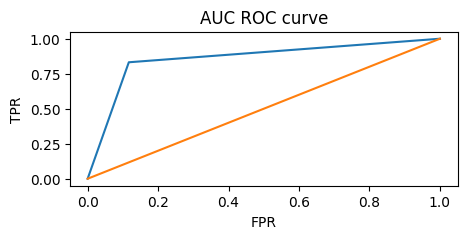

In [ ]:
plt.figure(figsize=(5,2))
plt.plot(fpr,tpr)
plt.plot([0,1],[0,1])
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('AUC ROC curve')
plt.show()

# Loss function in Logistic


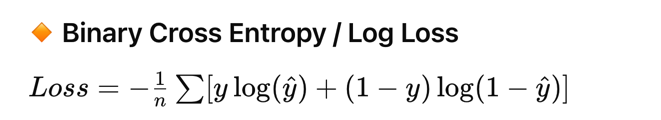

y --> actual value

y\hat --> predicted value

# KNN Classifier

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(x_sampled,y_sampled)
y_pred = knn_model.predict(x_test)

In [ ]:
confusion_matrix(y_test,y_pred)

array([[67, 10],
       [15, 92]])

In [ ]:
print('Accuracy_score: ',accuracy_score(y_test,y_pred))
print('precision_score: ',precision_score(y_test,y_pred))
print('recall_score: ',recall_score(y_test,y_pred))
print('f1_score: ',f1_score(y_test,y_pred))

Accuracy_score:  0.8641304347826086
precision_score:  0.9019607843137255
recall_score:  0.8598130841121495
f1_score:  0.8803827751196173


**How to select K value**

In [ ]:
error=[]
for k in range(2,10):
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(x_sampled,y_sampled)
  y_pred = knn.predict(x_test)
  error.append(np.mean(y_test!=y_pred))

In [ ]:
error

[np.float64(0.2608695652173913),
 np.float64(0.16847826086956522),
 np.float64(0.1793478260869565),
 np.float64(0.1358695652173913),
 np.float64(0.15760869565217392),
 np.float64(0.1358695652173913),
 np.float64(0.16847826086956522),
 np.float64(0.14673913043478262)]

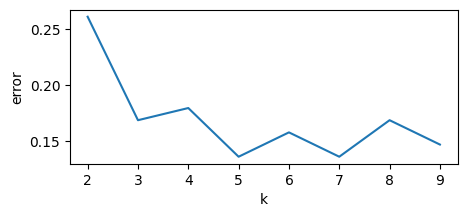

In [ ]:
plt.figure(figsize=(5,2))
plt.plot(range(2,10),error)
plt.xlabel('k')
plt.ylabel('error')
plt.show()

Optimal value for k is 7.

## **Decision Tree Classifier**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model= DecisionTreeClassifier(criterion='gini',splitter='best',max_depth=5,
                              max_features='sqrt',min_samples_split=5,
                              min_samples_leaf=3)
# train the model:x_sampled,y_sampled
model.fit(x_sampled,y_sampled)
# predictions: x_test
y_pred = model.predict(x_test)


In [ ]:
print("Confusion matrix: ",confusion_matrix(y_test,y_pred))
print("Accuracy score",accuracy_score(y_test,y_pred))
print("Precision score",precision_score(y_test,y_pred))
print("Recall_score",recall_score(y_test,y_pred))
print("f1_score",f1_score(y_test,y_pred))

# Model performance increased after adding hyperparameters

Confusion matrix:  [[66 11]
 [25 82]]
Accuracy score 0.8043478260869565
Precision score 0.8817204301075269
Recall_score 0.7663551401869159
f1_score 0.82


**Overfitting**

In [ ]:
# train accuracy
y_train_pred = model.predict(x_train)
accuracy_score(y_train,y_train_pred)

0.8623978201634878

In [ ]:
# test accuracy
accuracy_score(y_test,y_pred)

0.8043478260869565

## **Cross Validation**

Cross validation is used to train model using different samples and test model with different sets of data.

Instead using just train_test concept only once we train and test model multiple times.

**Why Cross Validation is Used?**
- Reduces overfitting
- Gives better model evaluation
- Uses data efficiently
- Helps select the best model
- Provides stable accuracy score

**Types of Cross validation**

- KFold Cross Validation
- Stratified Cross Validation

#### **KFold Cross validation**

K-Fold Cross Validation is a **model evaluation technique **where the dataset is **divided into K equal parts (folds).**

**The model is trained and tested K times:**

- Train on K−1 folds
- Test on 1 fold
- Repeat until every fold becomes the test set once.

**Final performance = Average of all scores**

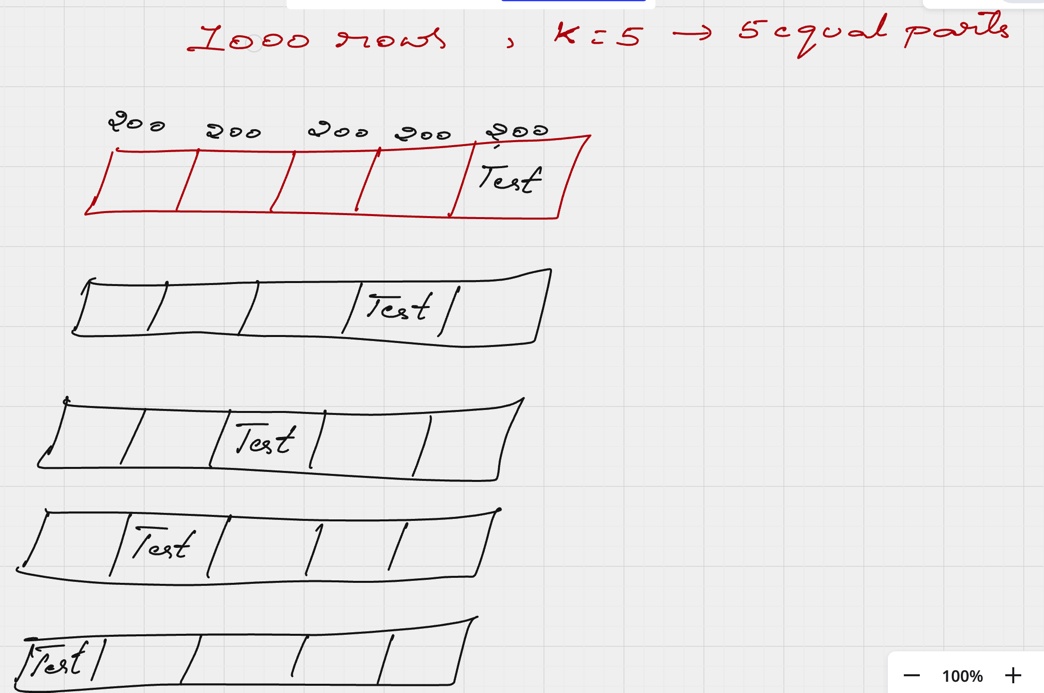

In [ ]:
# k Fold
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
model= DecisionTreeClassifier(criterion='gini',splitter='best',max_depth=5,
                              max_features='sqrt',min_samples_split=5,
                              min_samples_leaf=3)
kfold = KFold(n_splits=5,shuffle=True,random_state=42)
scores = cross_val_score(model,x_sampled,y_sampled,cv=kfold)
print(scores)
print('average score: ', np.mean(scores))

[0.8757764 0.8447205 0.825     0.80625   0.75     ]
average score:  0.8203493788819877


###**Stratified K-Fold Cross validation**

Stratified K-Fold is an improved version of **K-Fold Cross Validation** where the proportion of each class is maintained in every fold as original dataset proportion.

👉 Especially useful for imbalanced datasets.

**What Stratified KFold Does**

It ensures:
👉 Every fold has the same class distribution as the original dataset.

Example:

**Original dataset:**

90% class 0

10% class 1

**Every fold also maintains**:

90% class 0

10% class 1

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
model= DecisionTreeClassifier(criterion='gini',splitter='best',max_depth=5,
                              max_features='sqrt',min_samples_split=5,
                              min_samples_leaf=3)
sfold = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scores = cross_val_score(model,x_sampled,y_sampled,cv=sfold)
print(scores)
print('average score: ', np.mean(scores))

[0.85093168 0.8136646  0.775      0.8625     0.8125    ]
average score:  0.8229192546583851


###  **Hyperparameter Tuning**

Hyperparameter Tuning is the process of finding the **best hyperparameter values** for a machine learning model to i**mprove performance**.

👉 Hyperparameters are set before training the model.

## **Types**
- Grid Search CV
- Randomised search CV

### **Grid Search CV**

Its a process of **selecting best hyperparameter** values among all **possible combinations** of hyperparameters.

**Eg:**

**Decision Tree**

Criterion=['gini','entropy']

max_depth = [5,10,15]

**All combinations of hyperparameters**

gini,5

gini,10

gini,15

entropy,5

entropy, 10

entropy,15

**Grid Search Cv** will train model with each combination using **Cross validation**. It selects the best one then use that best parameters to train a model.




In [ ]:
from sklearn.model_selection import GridSearchCV
model = DecisionTreeClassifier()
parameters = {'criterion':['gini','entropy'],
              'max_depth':[5,10,15,20,25],'max_features':['sqrt','log2'],
              'min_samples_split':[2,3,4,5,6,7,8],'min_samples_leaf':[2,3,4,5,6,7,8],
              'splitter':['best','random']}
grid = GridSearchCV(estimator=model,param_grid=parameters,cv=5)
grid.fit(x_sampled,y_sampled)


GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [5, 10, 15, 20, 25],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [2, 3, 4, 5, 6, 7, 8],
                         'min_samples_split': [2, 3, 4, 5, 6, 7, 8],
                         'splitter': ['best', 'random']})

In [ ]:
print(grid.best_params_)

{'criterion': 'gini', 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 6, 'min_samples_split': 8, 'splitter': 'random'}


In [ ]:
model= DecisionTreeClassifier(criterion='gini',splitter='best',max_depth=5,
                              max_features='sqrt',min_samples_split=5,
                              min_samples_leaf=4)
# train the model:x_sampled,y_sampled
model.fit(x_sampled,y_sampled)
# predictions: x_test
y_pred = model.predict(x_test)

In [ ]:
print("Confusion matrix: ",confusion_matrix(y_test,y_pred))
print("Accuracy score",accuracy_score(y_test,y_pred))
print("Precision score",precision_score(y_test,y_pred))
print("Recall_score",recall_score(y_test,y_pred))
print("f1_score",f1_score(y_test,y_pred))

Confusion matrix:  [[67 10]
 [28 79]]
Accuracy score 0.7934782608695652
Precision score 0.8876404494382022
Recall_score 0.7383177570093458
f1_score 0.8061224489795918


### **Randomized Search CV**

Its a process of **selecting best hyperparameter** values among **randomly selected combinations** of hyperparameters.

**Eg:**

**Decision Tree**

Criterion=['gini','entropy']

max_depth = [5,10,15]

**All combinations of hyperparameters**

gini,5

gini,10

gini,15

entropy,5

entropy, 10

entropy,15

**If we say select any 3 random combinations**

gini,15

entropy,5

entropy, 10

Now model will be trained on randomly selected hyperparameters and it will select best among them.




In [ ]:
from sklearn.model_selection import RandomizedSearchCV
model = DecisionTreeClassifier()
parameters = {'criterion':['gini','entropy'],
              'max_depth':[5,10,15,20,25],'max_features':['sqrt','log2'],
              'min_samples_split':[2,3,4,5,6,7,8],'min_samples_leaf':[2,3,4,5,6,7,8],
              'splitter':['best','random']}
random = RandomizedSearchCV(estimator=model,param_distributions=parameters,cv=5,n_iter=20)
random.fit(x_sampled,y_sampled)
#n_iter : how many random combinations

RandomizedSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_iter=20,
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'max_depth': [5, 10, 15, 20, 25],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [2, 3, 4, 5, 6, 7,
                                                             8],
                                        'min_samples_split': [2, 3, 4, 5, 6, 7,
                                                              8],
                                        'splitter': ['best', 'random']})

In [ ]:
print(grid.best_params_)

{'criterion': 'gini', 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 6, 'min_samples_split': 8, 'splitter': 'random'}


In [ ]:
model= DecisionTreeClassifier(criterion='entropy',splitter='best',max_depth=5,
                              max_features='log2',min_samples_split=5,
                              min_samples_leaf=4)
# train the model:x_sampled,y_sampled
model.fit(x_sampled,y_sampled)
# predictions: x_test
y_pred = model.predict(x_test)

In [ ]:
print("Confusion matrix: ",confusion_matrix(y_test,y_pred))
print("Accuracy score",accuracy_score(y_test,y_pred))
print("Precision score",precision_score(y_test,y_pred))
print("Recall_score",recall_score(y_test,y_pred))
print("f1_score",f1_score(y_test,y_pred))

Confusion matrix:  [[70  7]
 [36 71]]
Accuracy score 0.7663043478260869
Precision score 0.9102564102564102
Recall_score 0.6635514018691588
f1_score 0.7675675675675676


##**Limitations**

- Grid Search Cv will take time since it has to search for best one among all possible combinations.
- Randomised Search Cv will faster as it takes random combinations to select the best one but it might miss the best combination while selecting random Combination.
- GridSearch Cv is good as it search for best parameter among all combinations even though it takes time.

# **Random Forest Classifier**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(criterion='gini',max_depth=5,
                              max_features='sqrt',min_samples_split=3,
                              min_samples_leaf=5,n_estimators=10,bootstrap=True)
model.fit(x_sampled,y_sampled)
y_pred = model.predict(x_test)

In [ ]:
print("Confusion matrix: ",confusion_matrix(y_test,y_pred))
print("Accuracy score",accuracy_score(y_test,y_pred))
print("Precision score",precision_score(y_test,y_pred))
print("Recall_score",recall_score(y_test,y_pred))
print("f1_score",f1_score(y_test,y_pred))

Confusion matrix:  [[68  9]
 [18 89]]
Accuracy score 0.8532608695652174
Precision score 0.9081632653061225
Recall_score 0.8317757009345794
f1_score 0.8682926829268293


# **Gradient Boosting Classifier**

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
model = GradientBoostingClassifier(criterion='friedman_mse',max_depth=10,
                              max_features='sqrt',min_samples_split=3,
                              min_samples_leaf=5,n_estimators=10,loss='log_loss',
                                   learning_rate=0.01,subsample=0.8)
model.fit(x_sampled,y_sampled)
y_pred = model.predict(x_test)
# criterion -->'squared_error', 'friedman_mse'

In [ ]:
print("Confusion matrix: ",confusion_matrix(y_test,y_pred))
print("Accuracy score",accuracy_score(y_test,y_pred))
print("Precision score",precision_score(y_test,y_pred))
print("Recall_score",recall_score(y_test,y_pred))
print("f1_score",f1_score(y_test,y_pred))

Confusion matrix:  [[68  9]
 [16 91]]
Accuracy score 0.8641304347826086
Precision score 0.91
Recall_score 0.8504672897196262
f1_score 0.8792270531400966


# XGBClassifier

In [ ]:
from xgboost import XGBClassifier
model = XGBClassifier(n_estimators=10,max_depth=10,learning_rate=0.01,gamma=1 ,
                      reg_alpha=0.01 , reg_lambda=0.1, colsample_bytree=0.8
                      ,subsample=0.8 ,n_jobs=-1)
model.fit(x_sampled,y_sampled)
y_pred = model.predict(x_test)

In [ ]:
print("Confusion matrix: ",confusion_matrix(y_test,y_pred))
print("Accuracy score",accuracy_score(y_test,y_pred))
print("Precision score",precision_score(y_test,y_pred))
print("Recall_score",recall_score(y_test,y_pred))
print("f1_score",f1_score(y_test,y_pred))

Confusion matrix:  [[67 10]
 [21 86]]
Accuracy score 0.8315217391304348
Precision score 0.8958333333333334
Recall_score 0.8037383177570093
f1_score 0.8472906403940886


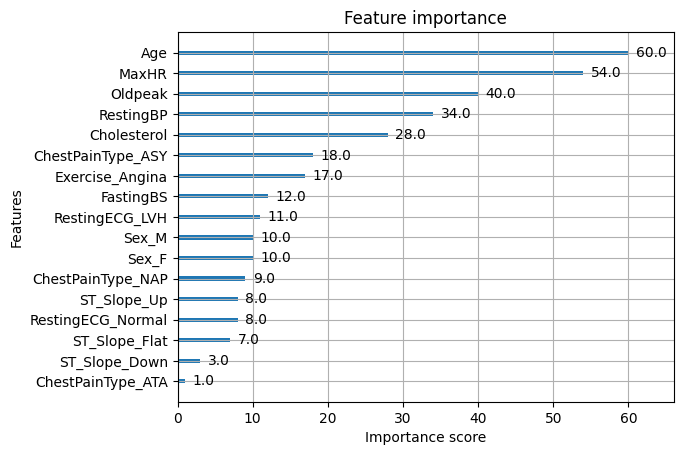

In [ ]:
# feature importance
from xgboost import plot_importance
import matplotlib.pyplot as plt

plot_importance(model)
plt.show()

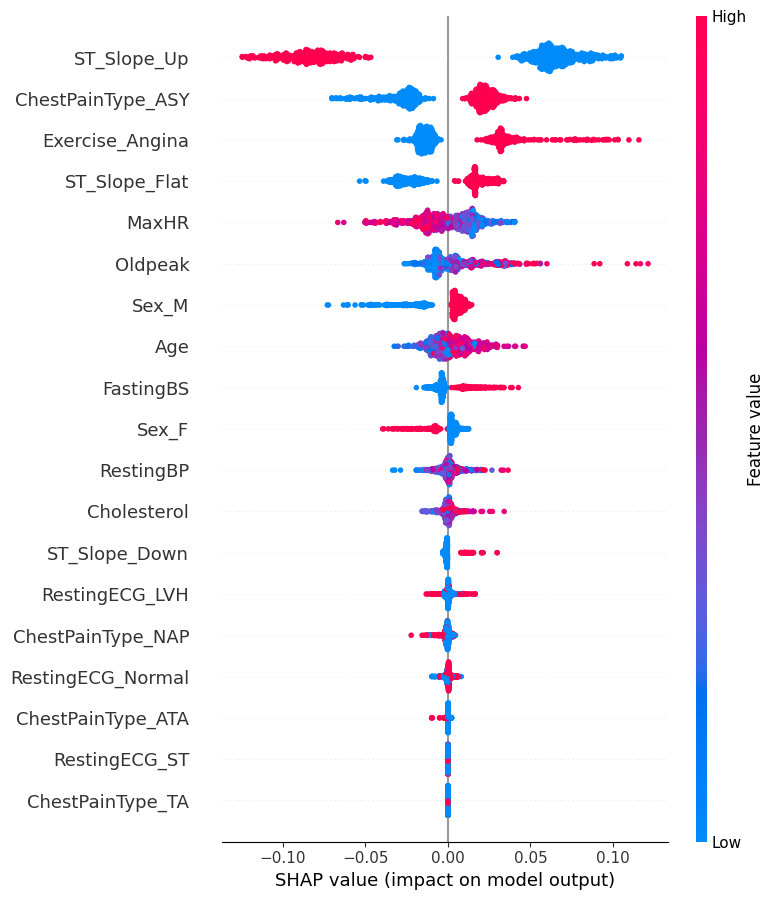

In [ ]:
# shap: explains positive and negative impact with output
import shap

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(x_train)

shap.summary_plot(
    shap_values,
    x_train
)

/usr/local/lib/python3.12/dist-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` insetad. 
  warnings.warn(


<Figure size 120000x60000 with 0 Axes>

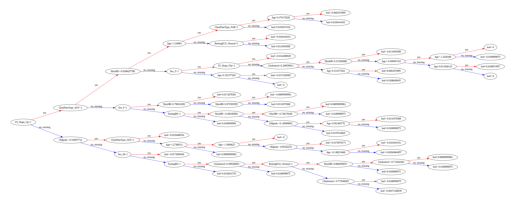

In [ ]:

from xgboost import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize=(400, 200), dpi=300)

plot_tree(
    model,
    num_trees=0,
    rankdir='LR'   # Left → Right layout
)

plt.show()

/usr/local/lib/python3.12/dist-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` insetad. 
  warnings.warn(


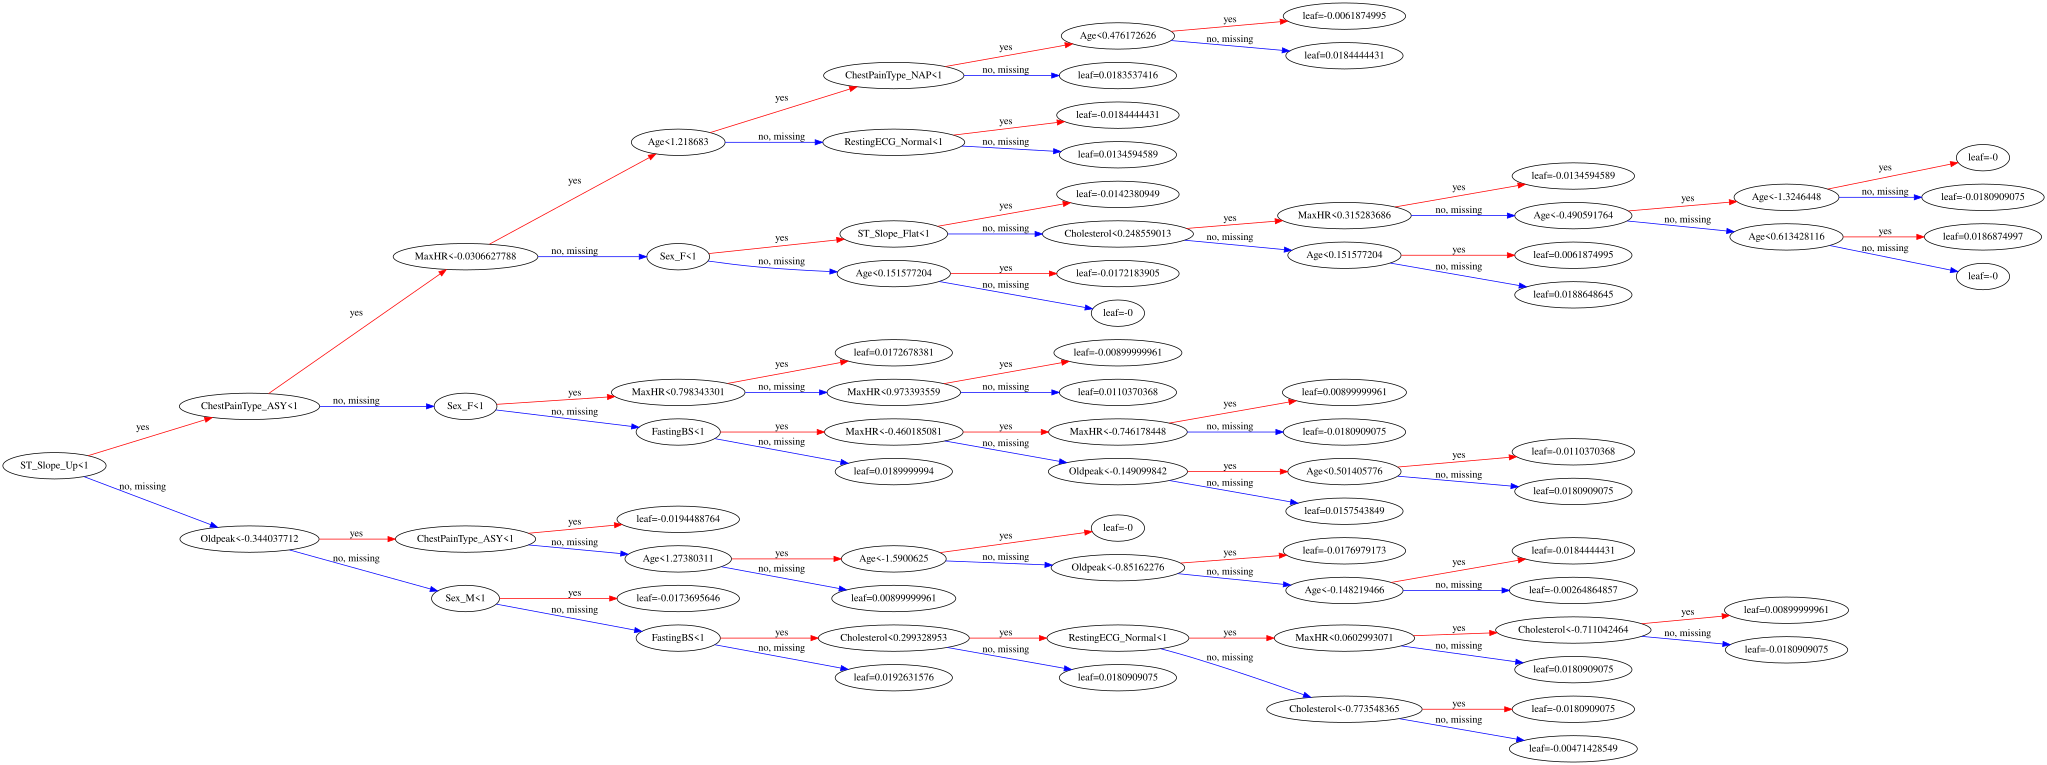

In [ ]:
from xgboost import to_graphviz

graph = to_graphviz(
    model,
    num_trees=0,
    rankdir='LR',
    yes_color='#0000FF',
    no_color='#FF0000'
)

graph

# Support Vector Classifier

In [ ]:
from sklearn.svm import SVC
model = SVC(kernel = 'rbf',C=1,gamma=0.01)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)

In [ ]:
print("Confusion matrix: ",confusion_matrix(y_test,y_pred))
print("Accuracy score",accuracy_score(y_test,y_pred))
print("Precision score",precision_score(y_test,y_pred))
print("Recall_score",recall_score(y_test,y_pred))
print("f1_score",f1_score(y_test,y_pred))

Confusion matrix:  [[67 10]
 [16 91]]
Accuracy score 0.8586956521739131
Precision score 0.900990099009901
Recall_score 0.8504672897196262
f1_score 0.875


In [ ]:
# save svm model as its recall score is high
import pickle
with open('svc.pkl','wb') as f:
  pickle.dump(model,f)